# Week 2 — Task 2: Data Cleaning & Exploratory Data Analysis
**Dataset:** Titanic (source: seaborn-data, https://github.com/mwaskom/seaborn-data)

Steps: load → missing values → duplicates → outliers → encoding → scaling → relationships → correlation → charts → feature importance.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif
sns.set_theme(style="whitegrid")
%matplotlib inline

## 1. Load and understand the dataset

In [2]:
df = pd.read_csv("titanic.csv")
print("Shape:", df.shape)
display(df.head())
display(df.describe(include="all").T.round(2))

Shape: (891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
survived,891.0,NaN,NaN,NaN,0.383838,0.486592,0.0,0.0,0.0,1.0,1.0
pclass,891.0,NaN,NaN,NaN,2.308642,0.836071,1.0,2.0,3.0,3.0,3.0
sex,891,2,male,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,714.0,NaN,NaN,NaN,29.699118,14.526497,0.42,20.125,28.0,38.0,80.0
sibsp,891.0,NaN,NaN,NaN,0.523008,1.102743,0.0,0.0,0.0,1.0,8.0
parch,891.0,NaN,NaN,NaN,0.381594,0.806057,0.0,0.0,0.0,0.0,6.0
fare,891.0,NaN,NaN,NaN,32.204208,49.693429,0.0,7.9104,14.4542,31.0,512.3292
embarked,889,3,S,644,NaN,NaN,NaN,NaN,NaN,NaN,NaN
class,891,3,Third,491,NaN,NaN,NaN,NaN,NaN,NaN,NaN
who,891,3,man,537,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Column meaning:** `survived` (target: 1 = survived), `pclass` (ticket class), `sex`, `age`, `sibsp` (siblings/spouses aboard), `parch` (parents/children aboard), `fare`, `embarked` (port S/C/Q). Columns `class`, `who`, `adult_male`, `deck`, `embark_town`, `alive`, `alone` are derived or duplicate versions of the others.

## 2. Handle missing values

In [3]:
miss = df.isnull().sum()
display(pd.DataFrame({"missing": miss, "percent": (miss/len(df)*100).round(2)})[miss > 0])

,missing,percent
age,177,19.87
embarked,2,0.22
deck,688,77.22
embark_town,2,0.22


**Decisions:** `deck` (77% missing) → dropped. `age` (20% missing) → median imputation grouped by `pclass` and `sex` (age differs by class, so this is more accurate than one global median). `embarked` (2 missing) → mode.

In [4]:
df = df.drop(columns=["deck"])
df["age"] = df["age"].fillna(df.groupby(["pclass", "sex"])["age"].transform("median"))
df["embarked"] = df["embarked"].fillna(df["embarked"].mode()[0])
print("Remaining missing:", df.drop(columns=["embark_town"]).isnull().sum().sum())

Remaining missing: 0


## 3. Remove duplicate records

In [5]:
print("Duplicates:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after:", df.shape)

Duplicates: 118
Shape after: (773, 14)


## 4. Identify potential outliers (IQR method + boxplots)

,feature,lower_bound,upper_bound,n_outliers
0,age,-4.50,63.50,13
1,fare,-31.44,73.86,97
2,sibsp,-1.50,2.50,39
3,parch,-1.50,2.50,15


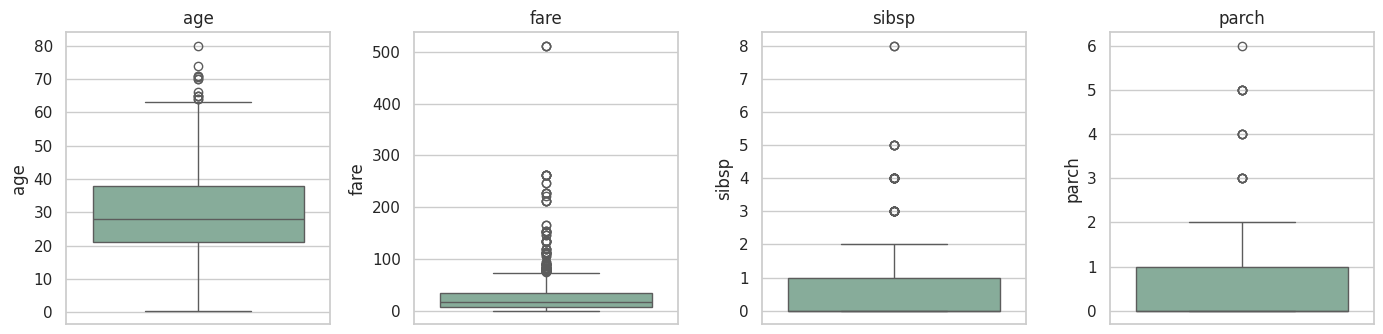

In [6]:
num_cols = ["age", "fare", "sibsp", "parch"]
rows = []
for c in num_cols:
    q1, q3 = df[c].quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
    rows.append([c, round(lo,2), round(hi,2), int(((df[c] < lo) | (df[c] > hi)).sum())])
display(pd.DataFrame(rows, columns=["feature", "lower_bound", "upper_bound", "n_outliers"]))
fig, ax = plt.subplots(1, 4, figsize=(14, 3.5))
for a, c in zip(ax, num_cols):
    sns.boxplot(y=df[c], ax=a, color="#81b29a"); a.set_title(c)
plt.tight_layout(); plt.savefig("eda1_outlier_boxplots.png", dpi=150); plt.show()

**Decision:** Fares above 512 are real first-class tickets, and large families are real, so these are not errors. Only the extreme `fare` tail is capped at the 99th percentile to limit its influence on distance/linear models. `sibsp` and `parch` are left as-is because they are combined into `family_size` below.

In [7]:
cap = df["fare"].quantile(0.99)
print(f"Fare 99th percentile cap: {cap:.2f}  | values capped: {(df['fare'] > cap).sum()}")
df["fare"] = df["fare"].clip(upper=cap)

Fare 99th percentile cap: 262.38  | values capped: 7


## 5. Feature engineering and encoding categorical variables

Redundant columns dropped: `class` (= `pclass`), `alive` (= target), `who` and `adult_male` (derived from `sex`/`age`), `embark_town` (= `embarked`), `alone` (replaced by `is_alone`). New features: `family_size = sibsp + parch + 1`, `is_alone`. Encoding: `sex` → binary (male = 1); `embarked` → one-hot.

In [8]:
df["family_size"] = df["sibsp"] + df["parch"] + 1
df["is_alone"] = (df["family_size"] == 1).astype(int)
eda = df.copy()      # human-readable copy for plots
df = df.drop(columns=["class", "alive", "who", "adult_male", "embark_town", "alone"])
df["sex"] = (df["sex"] == "male").astype(int)
df = pd.get_dummies(df, columns=["embarked"], prefix="embarked", dtype=int)
display(df.head())
print(df.dtypes.value_counts())

,survived,pclass,sex,age,sibsp,parch,fare,family_size,is_alone,embarked_C,embarked_Q,embarked_S
0,0,3,1,22.0,1,0,7.2500,2,0,0,0,1
1,1,1,0,38.0,1,0,71.2833,2,0,1,0,0
2,1,3,0,26.0,0,0,7.9250,1,1,0,0,1
3,1,1,0,35.0,1,0,53.1000,2,0,0,0,1
4,0,3,1,35.0,0,0,8.0500,1,1,0,0,1


int64      10
float64     2
Name: count, dtype: int64


## 6. Feature scaling

Distance/gradient-based models (KNN, logistic regression, SVM) are sensitive to feature scale, so `age`, `fare`, and `family_size` are standardized (mean 0, std 1). Binary and one-hot columns are left unscaled. Tree models do not need scaling, so both versions are saved.

In [9]:
df.to_csv("titanic_week2_cleaned.csv", index=False)
scaled = df.copy()
to_scale = ["age", "fare", "family_size"]
scaled[to_scale] = StandardScaler().fit_transform(scaled[to_scale])
scaled.to_csv("titanic_week2_scaled.csv", index=False)
display(scaled[to_scale].describe().loc[["mean", "std"]].round(3))

,age,fare,family_size
mean,0.000,0.000,0.000
std,1.001,1.001,1.001


## 7. Relationships between variables

/tmp/ipykernel_89/474911948.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=eda, x="sex", y="survived", ax=ax[0,0], palette="Set2", errorbar=None); ax[0,0].set_title("Survival rate by sex")
/tmp/ipykernel_89/474911948.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=eda, x="pclass", y="survived", ax=ax[0,1], palette="Set2", errorbar=None); ax[0,1].set_title("Survival rate by class")
/tmp/ipykernel_89/474911948.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=eda, x="embarked", y="survived", ax=ax[0,2], palette="Set2"

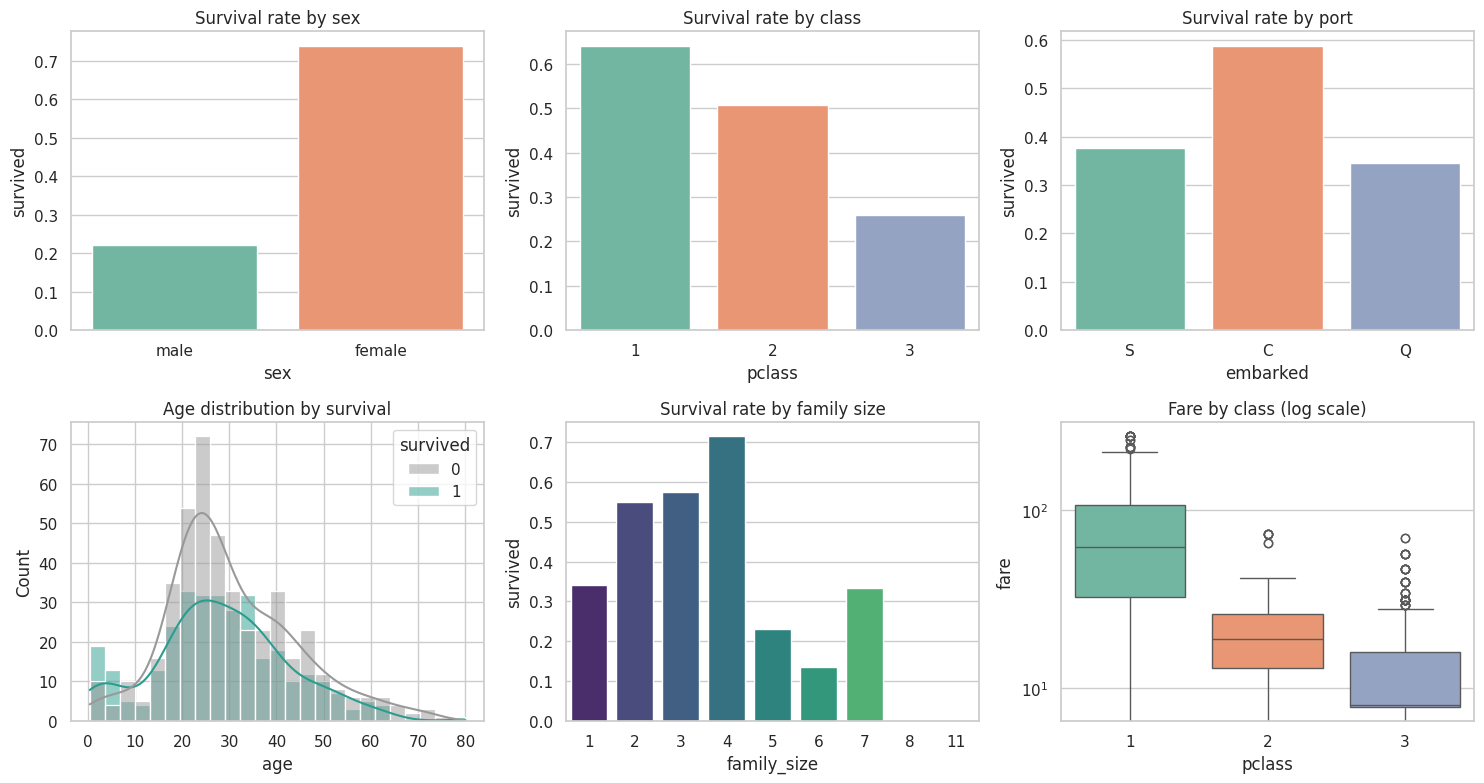

In [10]:
fig, ax = plt.subplots(2, 3, figsize=(15, 8))
sns.barplot(data=eda, x="sex", y="survived", ax=ax[0,0], palette="Set2", errorbar=None); ax[0,0].set_title("Survival rate by sex")
sns.barplot(data=eda, x="pclass", y="survived", ax=ax[0,1], palette="Set2", errorbar=None); ax[0,1].set_title("Survival rate by class")
sns.barplot(data=eda, x="embarked", y="survived", ax=ax[0,2], palette="Set2", errorbar=None); ax[0,2].set_title("Survival rate by port")
sns.histplot(data=eda, x="age", hue="survived", bins=25, kde=True, ax=ax[1,0], palette=["#999999", "#2a9d8f"]); ax[1,0].set_title("Age distribution by survival")
sns.barplot(data=eda, x="family_size", y="survived", ax=ax[1,1], palette="viridis", errorbar=None); ax[1,1].set_title("Survival rate by family size")
sns.boxplot(data=eda, x="pclass", y="fare", ax=ax[1,2], palette="Set2"); ax[1,2].set_yscale("log"); ax[1,2].set_title("Fare by class (log scale)")
plt.tight_layout(); plt.savefig("eda2_relationships.png", dpi=150); plt.show()

In [11]:
pd.options.display.float_format = "{:.3f}".format
print("Survival rate by sex x class:")
display(eda.pivot_table(values="survived", index="sex", columns="pclass", aggfunc="mean"))
print("Survival rate by age group:")
bins = pd.cut(eda["age"], [0, 12, 18, 35, 60, 100], labels=["child 0-12", "teen 13-18", "adult 19-35", "middle 36-60", "senior 60+"])
display(eda.groupby(bins, observed=True)["survived"].agg(["mean", "count"]))
print("Survival rate: alone vs not alone:")
display(eda.groupby("is_alone")["survived"].agg(["mean", "count"]))

Survival rate by sex x class:


pclass,1,2,3
sex,,,
female,0.967,0.917,0.472
male,0.385,0.185,0.161


Survival rate by age group:


,mean,count
age,,
child 0-12,0.574,68
teen 13-18,0.448,67
adult 19-35,0.406,409
middle 36-60,0.389,208
senior 60+,0.238,21


Survival rate: alone vs not alone:


,mean,count
is_alone,,
0,0.510,337
1,0.342,436


## 8. Correlation analysis

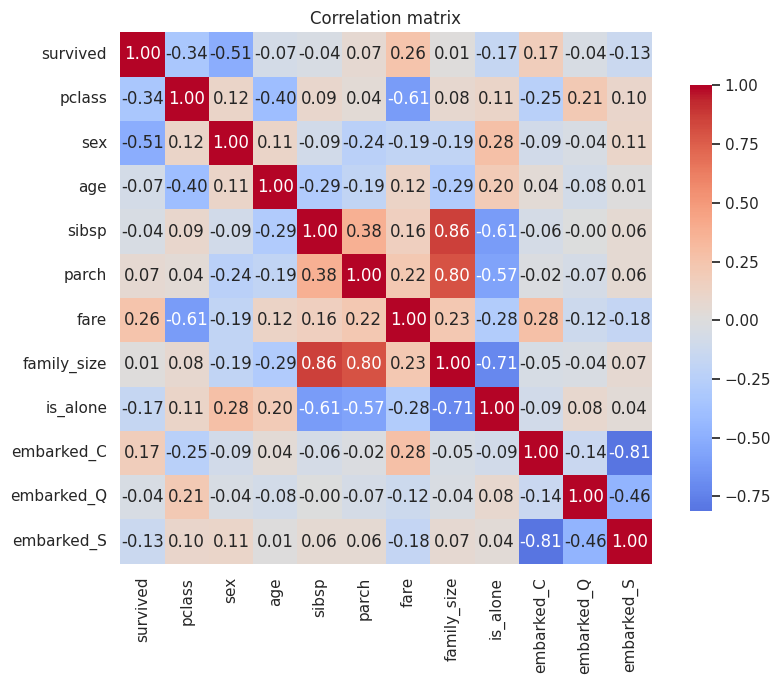

,corr_with_survived
sex,-0.510
pclass,-0.337
fare,0.257
embarked_C,0.174
is_alone,-0.170
embarked_S,-0.132
age,-0.074
parch,0.068
sibsp,-0.042
embarked_Q,-0.041


In [12]:
corr = df.corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, cbar_kws={"shrink": .8})
plt.title("Correlation matrix"); plt.tight_layout(); plt.savefig("eda3_correlation_heatmap.png", dpi=150); plt.show()
display(corr["survived"].drop("survived").sort_values(key=abs, ascending=False).to_frame("corr_with_survived"))

## 9. Additional charts

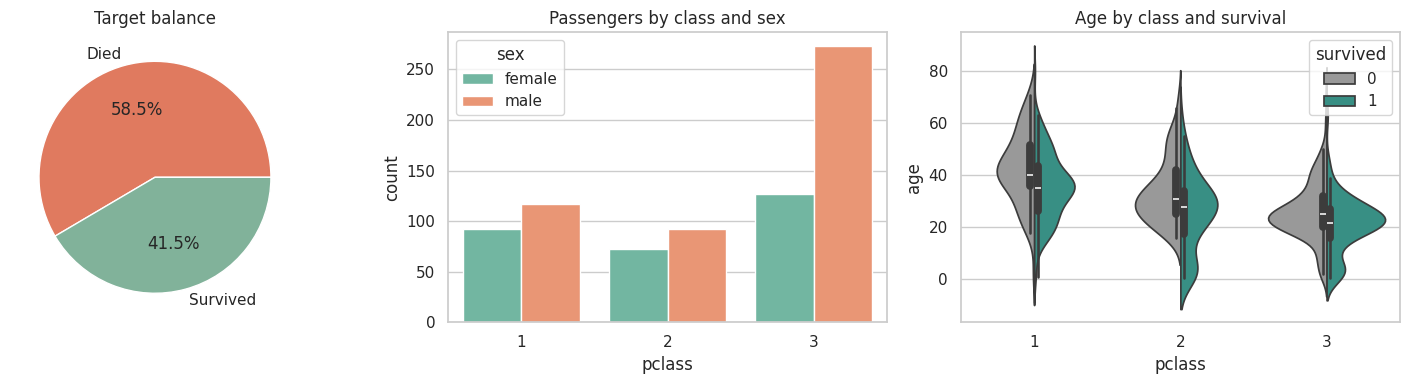

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
eda["survived"].map({0: "Died", 1: "Survived"}).value_counts().plot.pie(autopct="%1.1f%%", ax=ax[0], colors=["#e07a5f", "#81b29a"]); ax[0].set_ylabel(""); ax[0].set_title("Target balance")
sns.countplot(data=eda, x="pclass", hue="sex", ax=ax[1], palette="Set2"); ax[1].set_title("Passengers by class and sex")
sns.violinplot(data=eda, x="pclass", y="age", hue="survived", split=True, ax=ax[2], palette=["#999999", "#2a9d8f"]); ax[2].set_title("Age by class and survival")
plt.tight_layout(); plt.savefig("eda4_additional_charts.png", dpi=150); plt.show()

## 10. Most important features

Two independent methods are used: **mutual information** (captures non-linear dependence) and **Random Forest importance**.

,mutual_info,rf_importance
age,0.023,0.275
fare,0.120,0.274
sex,0.136,0.227
pclass,0.108,0.084
family_size,0.017,0.044
sibsp,0.038,0.027
parch,0.034,0.025
embarked_C,0.000,0.015
embarked_S,0.000,0.012
is_alone,0.024,0.011


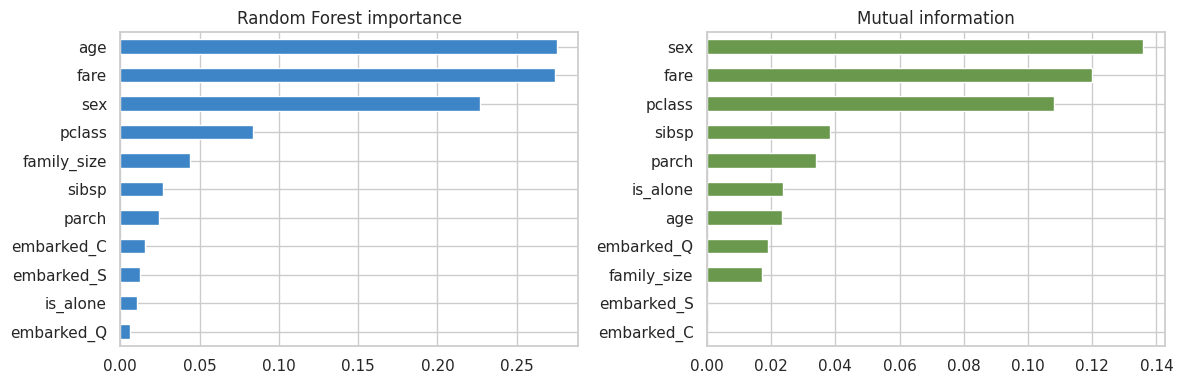

In [14]:
X, y = df.drop(columns="survived"), df["survived"]
mi = pd.Series(mutual_info_classif(X, y, random_state=42), index=X.columns)
rf = RandomForestClassifier(n_estimators=300, random_state=42).fit(X, y)
imp = pd.Series(rf.feature_importances_, index=X.columns)
res = pd.DataFrame({"mutual_info": mi, "rf_importance": imp}).sort_values("rf_importance", ascending=False)
display(res.round(3))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
res["rf_importance"].sort_values().plot.barh(ax=ax[0], color="#3d85c6"); ax[0].set_title("Random Forest importance")
res["mutual_info"].sort_values().plot.barh(ax=ax[1], color="#6a994e"); ax[1].set_title("Mutual information")
plt.tight_layout(); plt.savefig("eda5_feature_importance.png", dpi=150); plt.show()

In [15]:
print("Final cleaned shape:", df.shape, "| missing:", df.isnull().sum().sum())

Final cleaned shape: (773, 12) | missing: 0
